In [1]:
%pip install --upgrade pip
%pip install torch torchvision numpy

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import torch 
import torchvision
import torch.nn as nn
import numpy as np
import torchvision.transforms as transforms
import os
import pandas as pd
from torch.utils.data import DataLoader, Subset

In [3]:
mean = (0.5071, 0.4867, 0.4408)
std = (0.2675, 0.2565, 0.2761)

# Training: augmentation + normalisation
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Validation/test: no augmentation
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Load CIFAR-100 training data twice so train and validation
# can use different transforms
full_train = torchvision.datasets.CIFAR100(
    root='./data/CIFAR-100',
    train=True,
    download=True,
    transform=train_transform
)

full_val = torchvision.datasets.CIFAR100(
    root='./data/CIFAR-100',
    train=True,
    download=True,
    transform=eval_transform
)

# Official CIFAR-100 test set
test_dataset = torchvision.datasets.CIFAR100(
    root='./data/CIFAR-100',
    train=False,
    download=True,
    transform=eval_transform
)

Stratified split

In [4]:
rng = np.random.default_rng(42)

targets = np.array(full_train.targets)

train_indices = []
val_indices = []

for class_id in range(100):
    indices = np.where(targets == class_id)[0]
    rng.shuffle(indices)

    train_indices.extend(indices[:450])
    val_indices.extend(indices[450:])

# Shuffle the order while keeping exactly 450/50 images per class
train_indices = rng.permutation(train_indices).tolist()
val_indices = rng.permutation(val_indices).tolist()

train_dataset = Subset(full_train, train_indices)
val_dataset = Subset(full_val, val_indices)

print(len(train_dataset))  # 45000
print(len(val_dataset))    # 5000
print(len(test_dataset))   # 10000

45000
5000
10000


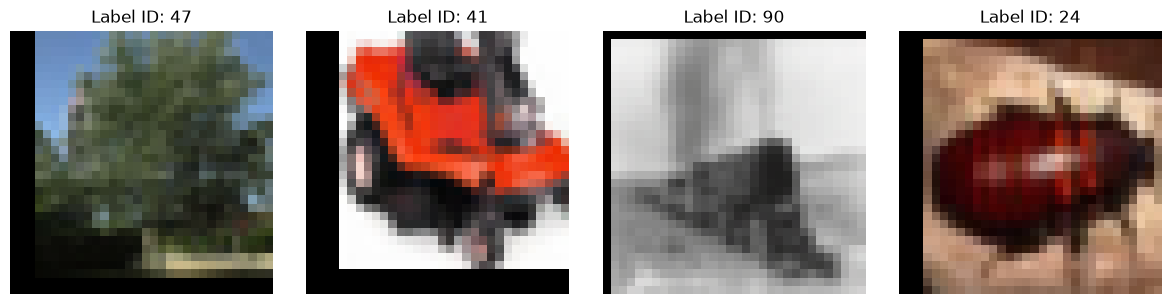

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Grab a few samples from the dataset
num_images = 4
fig, axes = plt.subplots(1, num_images, figsize=(12, 3))

# CIFAR-100 mean and std used in your transform (needed to reverse normalisation)
mean = np.array([0.5071, 0.4867, 0.4408])
std = np.array([0.2675, 0.2565, 0.2761])

for i in range(num_images):
    # Fetch the image tensor and integer label
    img_tensor, label = train_dataset[i]
    
    # Convert tensor from (Channels, Height, Width) to standard numpy (Height, Width, Channels)
    img_np = img_tensor.permute(1, 2, 0).numpy()
    
    # Reverse the normalisation: (pixel * std) + mean
    img_np = (img_np * std) + mean
    img_np = np.clip(img_np, 0, 1)  # Ensure values stay strictly between 0 and 1
    
    # Plot the image
    axes[i].imshow(img_np)
    axes[i].set_title(f"Label ID: {label}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

Now we build + train our first model

In [6]:
# Define the device (checks for GPU, Apple Silicon MPS, or falls back to CPU)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")  # For Apple Silicon
else:
    device = torch.device("cpu")

In [7]:
# Hyperparameters
num_epochs = 1
num_classes = 100
batch_size = 16
learning_rate = 0.1

# Data loader
train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True
)

# ResNeXt-29 (8x64d)
class ResNeXtBottleneck(nn.Module):
    expansion = 4

    def __init__(self, in_channels, channels, stride=1, cardinality=8, base_width=64):
        super().__init__()

        width = cardinality * base_width * channels // 64

        self.conv1 = nn.Conv2d(in_channels, width, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(width)

        self.conv2 = nn.Conv2d(
            width, width, 3,
            stride=stride, padding=1,
            groups=cardinality, bias=False
        )
        self.bn2 = nn.BatchNorm2d(width)

        self.conv3 = nn.Conv2d(width, channels * self.expansion, 1, bias=False)
        self.bn3 = nn.BatchNorm2d(channels * self.expansion)

        self.shortcut = nn.Sequential(
            nn.Conv2d(in_channels, channels * self.expansion, 1, stride=stride, bias=False),
            nn.BatchNorm2d(channels * self.expansion)
        ) if stride != 1 or in_channels != channels * self.expansion else nn.Identity()

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        residual = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))

        return self.relu(out + residual)


class ResNeXt29(nn.Module):
    def __init__(self, num_classes=100):
        super().__init__()

        self.in_channels = 64

        self.input_flow = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.stage1 = self._make_stage(64, 3, stride=1)
        self.stage2 = self._make_stage(128, 3, stride=2)
        self.stage3 = self._make_stage(256, 3, stride=2)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(1024, num_classes)

    def _make_stage(self, channels, blocks, stride):
        layers = [ResNeXtBottleneck(self.in_channels, channels, stride)]
        self.in_channels = channels * 4

        for _ in range(1, blocks):
            layers.append(ResNeXtBottleneck(self.in_channels, channels))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.input_flow(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


model = ResNeXt29(num_classes).to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=learning_rate,
    momentum=0.9,
    weight_decay=5e-4
)

scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=[150, 225], gamma=0.1
)

# Train the model
total_step = len(train_loader)

for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (i + 1) % 100 == 0:
            print(
                'Epoch [{}/{}], Step [{}/{}], Loss: {:.4f}'
                .format(epoch + 1, num_epochs, i + 1, total_step, loss.item())
            )

    scheduler.step()

Epoch [1/1], Step [100/2813], Loss: 4.4718
Epoch [1/1], Step [200/2813], Loss: 4.6537
Epoch [1/1], Step [300/2813], Loss: 4.5926
Epoch [1/1], Step [400/2813], Loss: 4.6383
Epoch [1/1], Step [500/2813], Loss: 4.4372
Epoch [1/1], Step [600/2813], Loss: 4.3408
Epoch [1/1], Step [700/2813], Loss: 4.3944
Epoch [1/1], Step [800/2813], Loss: 4.2867
Epoch [1/1], Step [900/2813], Loss: 4.2788
Epoch [1/1], Step [1000/2813], Loss: 4.6766
Epoch [1/1], Step [1100/2813], Loss: 4.2787
Epoch [1/1], Step [1200/2813], Loss: 4.4298
Epoch [1/1], Step [1300/2813], Loss: 4.2340
Epoch [1/1], Step [1400/2813], Loss: 4.3576
Epoch [1/1], Step [1500/2813], Loss: 4.1612
Epoch [1/1], Step [1600/2813], Loss: 4.1187
Epoch [1/1], Step [1700/2813], Loss: 4.4636
Epoch [1/1], Step [1800/2813], Loss: 5.0410
Epoch [1/1], Step [1900/2813], Loss: 4.2752
Epoch [1/1], Step [2000/2813], Loss: 4.2188
Epoch [1/1], Step [2100/2813], Loss: 4.1420
Epoch [1/1], Step [2200/2813], Loss: 4.5376
Epoch [1/1], Step [2300/2813], Loss: 4.73